# Imágenes médicas con Python

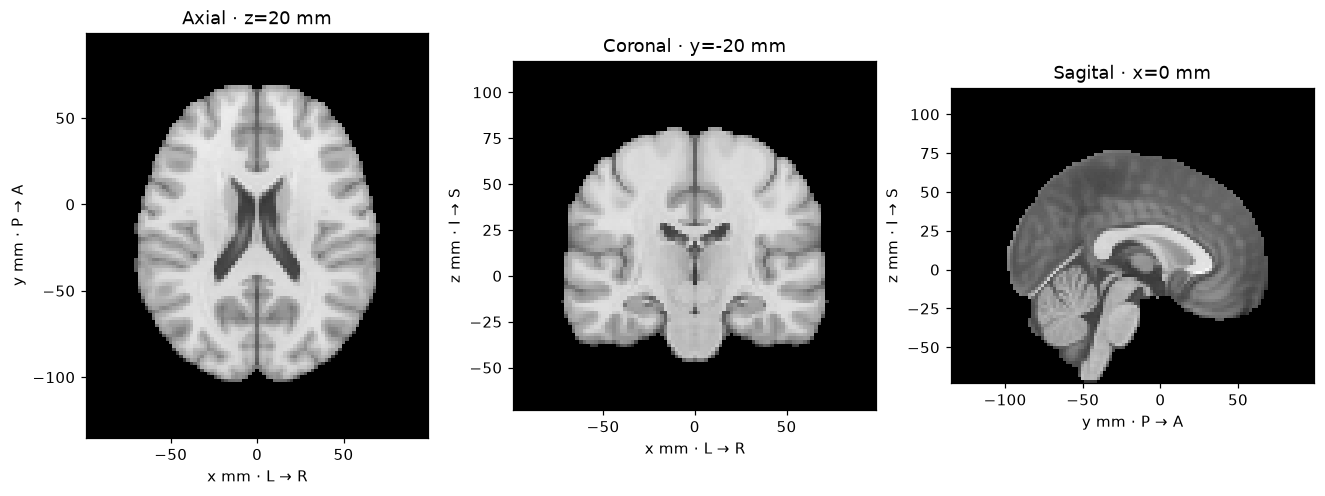

Son tres planos del mismo volumen **MNI152**, una referencia construida a partir de imágenes de muchas personas; no es el estudio de un paciente. **Nilearn** es una biblioteca de Python que permite cargar esta plantilla. Cada tono de gris representa una intensidad.

Ejecuta las celdas en orden con **Mayús + Enter**. Las figuras guardadas permiten mirar antes de ejecutar; los deslizadores aparecen al ejecutar su código.


## 01 · Preparar Python

Una biblioteca reúne funciones ya escritas. `find_spec` comprueba si una biblioteca está instalada; `if faltantes` ejecuta la instalación sólo cuando hace falta. `sys.executable` identifica el Python de esta sesión y `subprocess.check_call` ejecuta su instalador. Esta celda necesita internet si falta alguna biblioteca.

`Path` representa una ruta. `ruta.exists()` comprueba si el archivo público acompaña al cuaderno; en Colab se cargará la copia incluida en Nilearn.


In [1]:
import sys, subprocess, importlib.util
from pathlib import Path
ruta = Path("datos/mni152_2mm.nii.gz")
requisitos = {"numpy": "numpy>=1.22.4,<3", "matplotlib": "matplotlib>=3.8,<4",
              "nibabel": "nibabel>=5.2,<6", "scipy": "scipy>=1.8,<2",
              "ipywidgets": "ipywidgets>=8.1,<9", "pydicom": "pydicom>=3,<4"}
if not ruta.exists():
    requisitos["nilearn"] = "nilearn==0.12.1"
faltantes = [paquete for modulo, paquete in requisitos.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Bibliotecas disponibles.")


Bibliotecas disponibles.


## 02 · Importar las herramientas

`import` permite usar una biblioteca; `as` le asigna un nombre corto. NumPy (`np`) calcula con matrices; Matplotlib (`plt`) dibuja; NiBabel (`nib`) lee NIfTI; `ndimage` aplica filtros; pydicom interpreta datos DICOM. `widgets` crea controles y `display` los muestra. En Colab, el gestor de widgets habilita esos controles.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import pydicom
from scipy import ndimage
import ipywidgets as widgets
from IPython.display import display
if "google.colab" in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()
print("Herramientas listas para leer, calcular y dibujar.")


Herramientas listas para leer, calcular y dibujar.


## 03 · Cargar un archivo NIfTI

**NIfTI** guarda una matriz de imagen y la información necesaria para situarla en el espacio. `nib.load(ruta)` abre el archivo que acompaña al cuaderno. Si no existe, `load_mni152_template(resolution=2)` carga la plantilla pública que distribuye Nilearn, remuestreada a 2 mm.

Esta plantilla tiene intensidades relativas reescaladas; no son unidades Hounsfield ni identifican por sí solas un tejido.


In [3]:
if ruta.exists():
    imagen = nib.load(ruta)
    fuente = "Plantilla pública local: datos/mni152_2mm.nii.gz"
else:
    from nilearn.datasets import load_mni152_template
    imagen = load_mni152_template(resolution=2)
    fuente = "Plantilla MNI152 distribuida por Nilearn"
print(fuente)


Plantilla pública local: datos/mni152_2mm.nii.gz


## 04 · Vóxeles, forma y milímetros

Un **píxel** ocupa una casilla de una imagen 2D; un **vóxel** ocupa una casilla con volumen en 3D. `get_fdata` obtiene los números como decimales; `shape` cuenta casillas por eje y `get_zooms()[:3]` obtiene su separación física.

`affine` transforma índices en coordenadas. En esta plantilla los ejes están alineados y separados 2 mm: cada coordenada es el origen más la separación multiplicada por el índice. `np.arange` genera esos índices. `as_closest_canonical` ordena los ejes hacia derecha (**R**), anterior (**A**) y superior (**S**); el `assert` comprueba que podemos usar esta fórmula sencilla. Una imagen oblicua requiere aplicar la matriz afín completa. `extension` añade medio vóxel en cada extremo para dibujar los bordes de las casillas.


In [4]:
imagen = nib.as_closest_canonical(imagen)
datos = imagen.get_fdata(dtype=np.float32)
pasos = np.array(imagen.header.get_zooms()[:3])
afin = imagen.affine
assert np.allclose(pasos, [2, 2, 2]) and np.allclose(afin[:3, :3], np.diag(pasos))
x = afin[0, 3] + pasos[0] * np.arange(datos.shape[0])
y = afin[1, 3] + pasos[1] * np.arange(datos.shape[1])
z = afin[2, 3] + pasos[2] * np.arange(datos.shape[2])
extension = [x[0]-1, x[-1]+1, y[0]-1, y[-1]+1]
z_min, z_max = int(z[0]), int(z[-1])
print("Forma:", datos.shape, "· separación:", pasos, "mm")
print("Orientación:", nib.aff2axcodes(afin), "· planos axiales:", z_min, "a", z_max, "mm")


Forma: (99, 117, 95) · separación: [2. 2. 2.] mm
Orientación: ('R', 'A', 'S') · planos axiales: -72 a 116 mm


## 05 · Mirar los tres planos

`:` selecciona todos los índices de un eje. Al fijar el tercero obtenemos un plano axial; al fijar el segundo, coronal; al fijar el primero, sagital. `.T` intercambia filas y columnas para dibujar los ejes indicados.

`subplots(1, 3)` crea tres paneles. `zip` reúne la imagen y sus etiquetas; `for` repite el dibujo. `imshow` dibuja los valores: `cmap="gray"` usa grises, `origin="lower"` pone el origen abajo y `extent` establece coordenadas en mm. `set` añade títulos y ejes; `show` presenta la figura. **L/R**, **P/A** e **I/S** significan izquierda/derecha, posterior/anterior e inferior/superior.


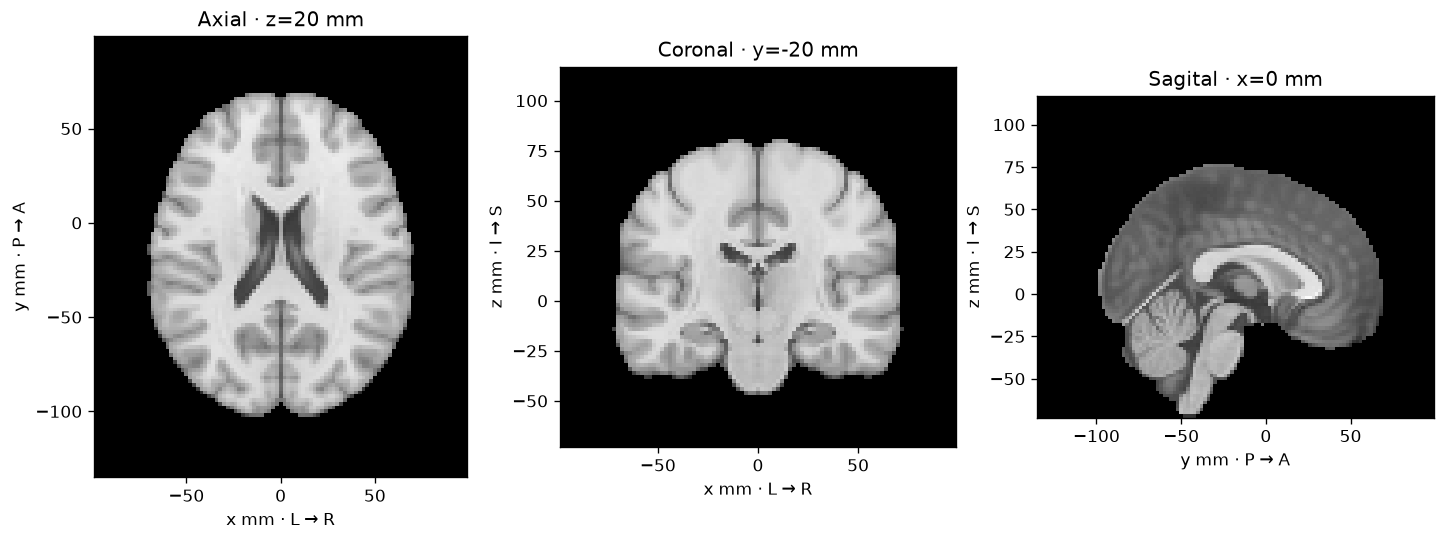

In [5]:
cortes = [datos[:, :, 46].T, datos[:, 57, :].T, datos[49, :, :].T]
extensiones = [extension, [x[0]-1, x[-1]+1, z[0]-1, z[-1]+1], [y[0]-1, y[-1]+1, z[0]-1, z[-1]+1]]
titulos = [f"Axial · z={z[46]:g} mm", f"Coronal · y={y[57]:g} mm", f"Sagital · x={x[49]:g} mm"]
ejes = [("x mm · L → R", "y mm · P → A"), ("x mm · L → R", "z mm · I → S"), ("y mm · P → A", "z mm · I → S")]
fig, ax = plt.subplots(1, 3, figsize=(12, 4.4), layout="constrained")
for panel, matriz, limites, titulo, etiquetas in zip(ax, cortes, extensiones, titulos, ejes):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=limites, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel=etiquetas[0], ylabel=etiquetas[1])
plt.show()


## 06 · Una imagen es una matriz

`np.array` reúne filas de números. Esta matriz ficticia tiene 6 filas y 6 columnas: 36 píxeles. `vmin=0` asigna negro al cero y `vmax=5`, blanco al cinco. `interpolation="nearest"` conserva las casillas visibles.

`np.ndenumerate` recorre cada posición y su valor. `text(columna, fila, valor)` escribe el número en el lugar correspondiente; Python cuenta desde cero. **Cambia un número en `juguete` y ejecuta de nuevo para cambiar su gris.**


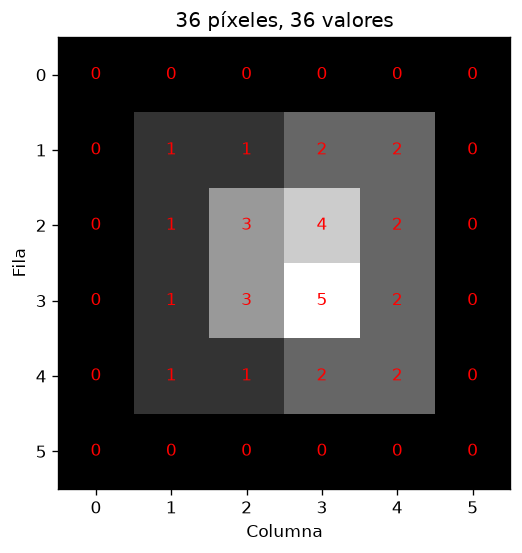

In [6]:
juguete = np.array([[0,0,0,0,0,0], [0,1,1,2,2,0], [0,1,3,4,2,0],
                    [0,1,3,5,2,0], [0,1,1,2,2,0], [0,0,0,0,0,0]], dtype=float)
fig, ax = plt.subplots(figsize=(5, 4.5), layout="constrained")
ax.imshow(juguete, cmap="gray", vmin=0, vmax=5, interpolation="nearest")
for (fila, columna), valor in np.ndenumerate(juguete):
    ax.text(columna, fila, int(valor), ha="center", va="center", color="red")
ax.set(title="36 píxeles, 36 valores", xlabel="Columna", ylabel="Fila")
plt.show()


## 07 · Leer y cambiar un píxel

`juguete[fila, columna]` selecciona una casilla: `[2, 3]` es la tercera fila y la cuarta columna. `.copy()` crea una matriz independiente; asignar cero en la copia no cambia el original. `=` asigna un valor; no es una comparación.

**Cambia `fila`, `columna` o `nuevo_valor` en estas primeras líneas y vuelve a ejecutar.** Ambos paneles usan la misma escala, para que un gris siempre signifique el mismo número.


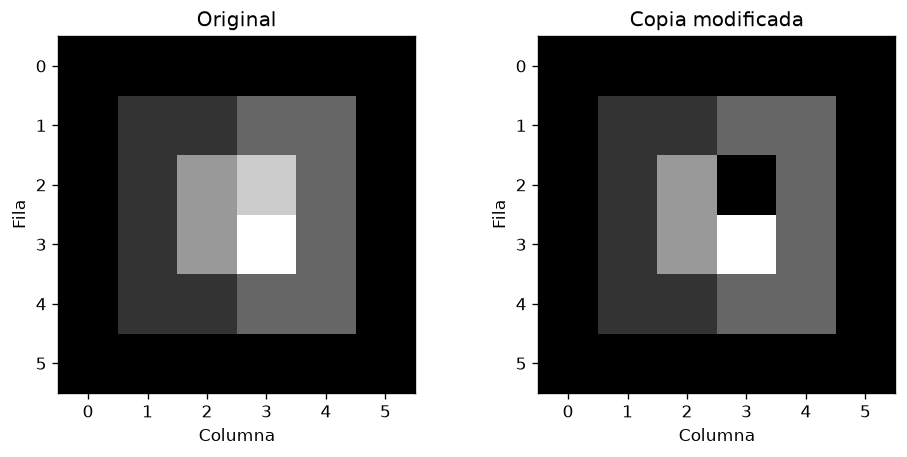

Original: 4.0 · copia: 0.0


In [7]:
fila, columna, nuevo_valor = 2, 3, 0
modificada = juguete.copy()
modificada[fila, columna] = nuevo_valor
fig, ax = plt.subplots(1, 2, figsize=(8, 3.7), layout="constrained")
for panel, matriz, titulo in zip(ax, [juguete, modificada], ["Original", "Copia modificada"]):
    panel.imshow(matriz, cmap="gray", vmin=0, vmax=5, interpolation="nearest")
    panel.set(title=titulo, xlabel="Columna", ylabel="Fila")
plt.show()
print("Original:", juguete[fila, columna], "· copia:", modificada[fila, columna])


## 08 · Encabezados DICOM: datos que describen la imagen

**DICOM** combina datos de imagen y metadatos del estudio, la adquisición y su geometría. Llamamos «encabezado» a esos metadatos; *File Meta Information* es una parte específica del archivo, no todos sus metadatos. Este ejemplo crea sólo un encabezado **sintético**, sin pacientes ni píxeles.

`Dataset()` crea el conjunto de elementos. Cada asignación añade un atributo. Al recorrerlo, `tag` es su identificador hexadecimal `(grupo, elemento)`, `keyword` es su nombre en Python, `VR` indica el tipo de valor y `value` contiene el dato. Por ejemplo, `US` es un entero sin signo, `CS` un código textual y `DS` un decimal representado como texto. `Rows`/`Columns` cuentan píxeles y `PixelSpacing` da la distancia entre sus centros **[fila, columna]**, en mm; `Modality="MR"` identifica resonancia.

Para un archivo propio, `pydicom.dcmread("imagen.dcm", stop_before_pixels=True)` lee hasta antes de `Pixel Data`, sin cargar los píxeles ni los elementos posteriores. **Eso no anonimiza.** Los metadatos pueden contener identificadores, y los propios píxeles pueden contener texto o rasgos reconocibles. Convertir a NIfTI o borrar sólo el nombre tampoco garantiza anonimato.


In [8]:
cabecera = pydicom.dataset.Dataset()
cabecera.Modality = "MR"
cabecera.Rows = 256
cabecera.Columns = 256
cabecera.PixelSpacing = [0.8, 0.8]
for elemento in cabecera:
    print(f"{elemento.tag}  {elemento.keyword:14}  VR={elemento.VR}  valor={elemento.value}")
print("Separación entre centros [fila, columna]:", cabecera.PixelSpacing, "mm")


(0008,0060)  Modality        VR=CS  valor=MR
(0028,0010)  Rows            VR=US  valor=256
(0028,0011)  Columns         VR=US  valor=256
(0028,0030)  PixelSpacing    VR=DS  valor=[0.8, 0.8]
Separación entre centros [fila, columna]: [0.8, 0.8] mm


## 09 · Elegir la posición de un corte

**Cambia `z_mm` de 20 a 25.** `np.abs(z-z_mm)` calcula la distancia de cada plano a la posición pedida; `.argmin()` localiza el más cercano. `int` convierte su índice a entero y `datos[:, :, k].T.copy()` extrae una copia del corte.

Índice y posición física no son lo mismo. La rejilla avanza de 2 en 2 mm: al pedir 25 mm, se muestra 24 mm porque `argmin` toma el menor índice en un empate.


In [9]:
z_mm = 20  # Posición que deseas consultar, en milímetros.
k = int(np.abs(z - z_mm).argmin())
corte = datos[:, :, k].T.copy()
print(f"Solicitado: {z_mm:g} mm · plano mostrado: {z[k]:g} mm · índice k={k}")


Solicitado: 20 mm · plano mostrado: 20 mm · índice k=46


## 10 · Cambiar el contraste

**Mueve `z_mm` o los extremos de `ventana` debajo del código.** El primer extremo se dibuja negro, el segundo blanco; los valores exteriores quedan saturados. Cambiar la ventana modifica la representación, no la matriz.

`def` define la función que se repetirá con cada cambio. `if` detecta límites iguales o invertidos; `return` termina esa ejecución. `vmin` y `vmax` fijan la ventana de `imshow`; `.suptitle` titula la figura completa. `widgets.interactive` conecta la función con sus argumentos: `IntSlider` mueve un entero y `FloatRangeSlider`, dos decimales. `continuous_update=False` recalcula al soltar. `display` coloca los controles junto al resultado.


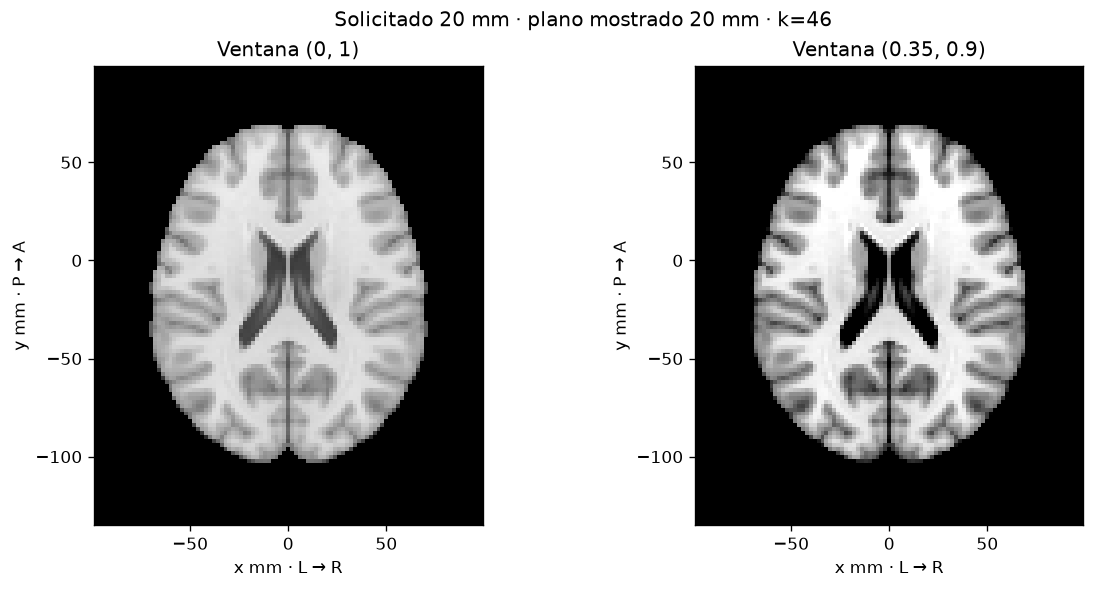

In [10]:
def ver_contraste(z_mm, ventana):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    if ventana[0] >= ventana[1]:
        print("Separa los dos extremos de la ventana: negro debe ser menor que blanco.")
        return
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.8), layout="constrained")
    for panel, limites in zip(ax, [(0, 1), ventana]):
        panel.imshow(corte, cmap="gray", origin="lower", extent=extension,
                     vmin=limites[0], vmax=limites[1])
        panel.set(title=f"Ventana {limites}", xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    return fig

control_contraste = widgets.interactive(
    ver_contraste,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    ventana=widgets.FloatRangeSlider(value=(0.35, 0.90), min=0, max=1, step=0.01, continuous_update=False),
)
display(control_contraste)


## 11 · Contar un histograma

Un **histograma** cuenta cuántos valores caen en cada intervalo. Su eje horizontal es intensidad, no posición. `.ravel()` reúne los 36 números; `np.arange` crea bordes a medio camino entre los enteros; `np.histogram` devuelve los conteos y los límites utilizados. `bar` dibuja una barra por intensidad.

Con la matriz inicial, los conteos son **20, 6, 6, 2, 1, 1**. Su suma es 36. Reordenar casillas conservando sus valores no cambia el histograma: se pierde información sobre dónde estaba cada píxel.


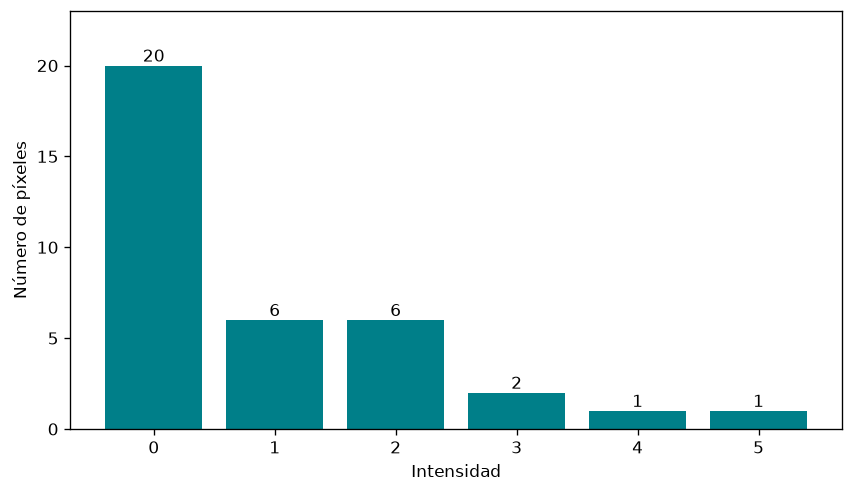

Conteos: [20  6  6  2  1  1] · total: 36


In [11]:
valores_juguete = juguete.ravel()
limites = np.arange(-0.5, 6.5, 1)
conteos, limites = np.histogram(valores_juguete, bins=limites)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.bar(np.arange(6), conteos, color="#007f89")
for intensidad, cantidad in enumerate(conteos):
    ax.text(intensidad, cantidad, str(cantidad), ha="center", va="bottom")
ax.set(xlabel="Intensidad", ylabel="Número de píxeles", ylim=(0, 23))
plt.show()
print("Conteos:", conteos, "· total:", conteos.sum())


## 12 · Histograma de un corte cerebral

**Mueve `bins` de 20 a 80:** habrá más intervalos y barras más estrechas, pero no nuevos píxeles. `z_mm` cambia el corte. El primer panel incluye el fondo; el segundo lo excluye.

`corte > 1e-6` produce una condición booleana y `corte[condición]` reúne los valores que la cumplen. Ese soporte excluye intensidades casi nulas; no es una segmentación anatómica. `hist(..., bins=bins, range=(0,1))` cuenta y dibuja en un rango fijo. `.size` cuenta elementos. El histograma puede tener picos por muchas razones; una barra alta no identifica enfermedad.


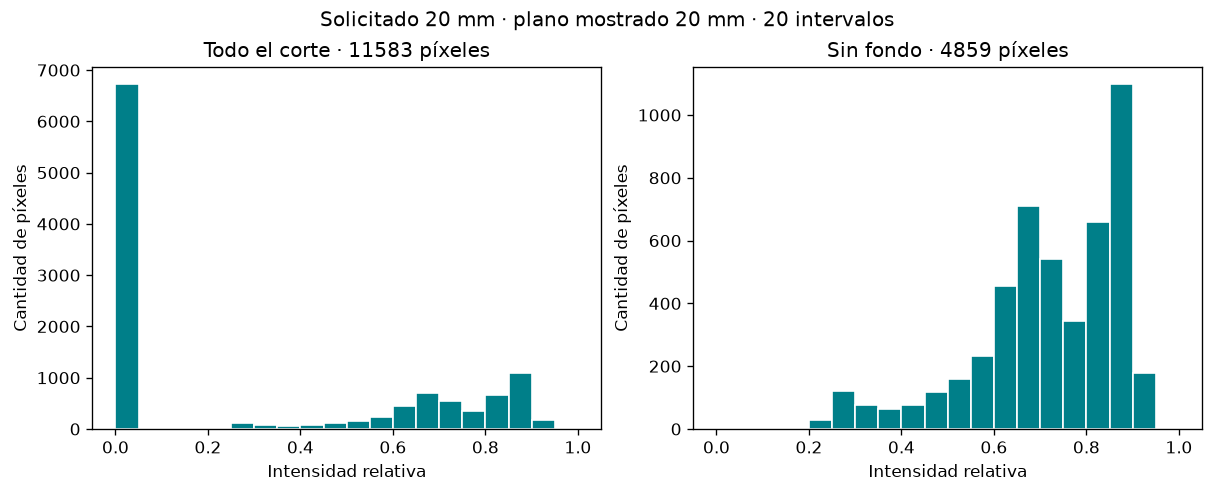

Total: 11583 · sin fondo: 4859 · excluidos: 6724


In [12]:
def ver_histograma(z_mm, bins):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    valores = corte[corte > 1e-6]
    fig, ax = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    for panel, muestra, nombre in zip(ax, [corte.ravel(), valores], ["Todo el corte", "Sin fondo"]):
        panel.hist(muestra, bins=bins, range=(0, 1), color="#007f89", edgecolor="white")
        panel.set(title=f"{nombre} · {muestra.size} píxeles",
                  xlabel="Intensidad relativa", ylabel="Cantidad de píxeles")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · {bins} intervalos")
    plt.show()
    print(f"Total: {corte.size} · sin fondo: {valores.size} · excluidos: {corte.size-valores.size}")
    return fig

control_histograma = widgets.interactive(
    ver_histograma,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    bins=widgets.IntSlider(value=20, min=5, max=100, step=5, continuous_update=False),
)
display(control_histograma)


## 13 · Percentil, umbral y máscara

`np.percentile(valores, percentil)` encuentra una intensidad según la posición porcentual de los valores ordenados. **Percentil 90 no significa intensidad 0.90.** `corte >= umbral` marca posiciones que alcanzan ese valor; `&` exige además pertenecer al soporte.

La máscara contiene `True`/`False`; `.sum()` cuenta los verdaderos como unos. Dividir entre la cantidad de valores del soporte obtiene la fracción seleccionada. Incluir empates con `>=` hace que no sea exactamente el 10 % superior. La máscara expresa una regla de intensidad, no una etiqueta de tejido. `if valores.size == 0` muestra un aviso si elegiste un corte sin intensidades analizables.


In [13]:
percentil = 90
soporte = corte > 1e-6
valores = corte[soporte]
if valores.size == 0:
    print("Este corte sólo contiene fondo; elige otra posición z_mm.")
else:
    umbral = np.percentile(valores, percentil)
    mascara = soporte & (corte >= umbral)
    porcentaje = 100 * mascara.sum() / valores.size
    print(f"p{percentil}: umbral={umbral:.6f}")
    print(f"Selección: {mascara.sum()} / {valores.size} = {porcentaje:.2f}%")


p90: umbral=0.878431
Selección: 523 / 4859 = 10.76%


## 14 · Ver cómo cambia la selección

**Mueve `percentil` de 90 a 75:** el umbral disminuye o permanece igual y la selección puede crecer. La función vuelve a extraer el corte y recalcula todos los valores cuando cambias un control.

`if valores.size == 0` evita calcular un percentil sin datos. `axvline` dibuja el umbral sobre el histograma; `legend` identifica esa línea. El segundo `imshow` dibuja la máscara: negro es `False`, blanco es `True`. `vmin=0, vmax=1` conserva esta interpretación. `IntSlider` limita el percentil a 0–100.


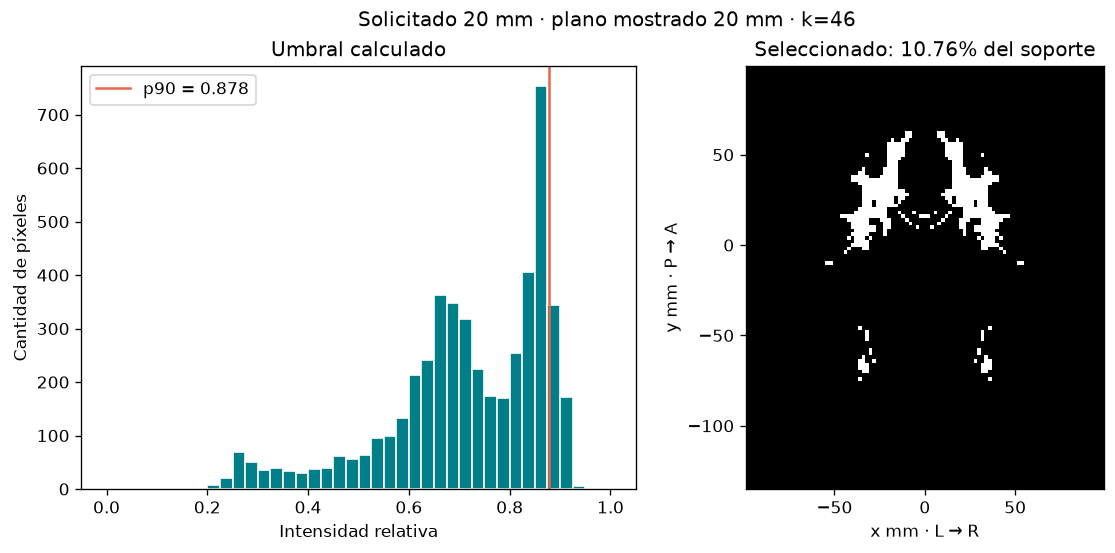

Umbral: 0.878431 · seleccionados: 523 / 4859


In [14]:
def ver_percentil(z_mm, percentil):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    soporte = corte > 1e-6
    valores = corte[soporte]
    if valores.size == 0:
        print(f"El plano {z[k]:g} mm sólo contiene fondo. Elige otra posición.")
        return
    umbral = np.percentile(valores, percentil)
    mascara = soporte & (corte >= umbral)
    porcentaje = 100 * mascara.sum() / valores.size
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
    ax[0].hist(valores, bins=40, range=(0, 1), color="#007f89", edgecolor="white")
    ax[0].axvline(umbral, color="#e9654b", label=f"p{percentil} = {umbral:.3f}")
    ax[0].legend()
    ax[0].set(xlabel="Intensidad relativa", ylabel="Cantidad de píxeles", title="Umbral calculado")
    ax[1].imshow(mascara, cmap="gray", origin="lower", extent=extension,
                 vmin=0, vmax=1, interpolation="nearest")
    ax[1].set(title=f"Seleccionado: {porcentaje:.2f}% del soporte", xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print(f"Umbral: {umbral:.6f} · seleccionados: {mascara.sum()} / {valores.size}")
    return fig

control_percentil = widgets.interactive(
    ver_percentil,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    percentil=widgets.IntSlider(value=90, min=0, max=100, continuous_update=False),
)
display(control_percentil)


## 15 · Curvas de nivel en una colina

Una curva de nivel une lugares con el mismo valor: altura en un mapa, intensidad en una imagen. `linspace` reparte coordenadas; `meshgrid` crea las rejillas X e Y; `exp` calcula una colina suave. `**2` eleva al cuadrado.

`contour(..., levels=niveles)` interpola líneas de igual valor y `clabel` escribe sus niveles. **Añade 0.9 a `niveles` y vuelve a ejecutar.** Una curva de nivel alto no significa un borde fuerte: indica un valor alto, no cuánto cambia entre vecinos.


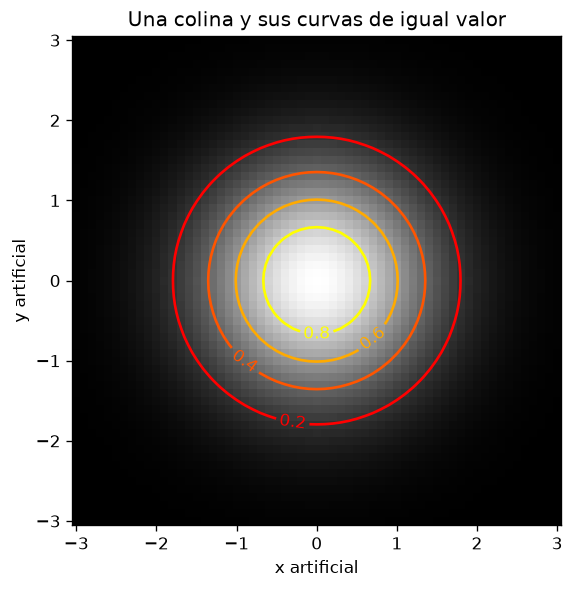

In [15]:
eje = np.linspace(-3, 3, 61)
X, Y = np.meshgrid(eje, eje)
colina = np.exp(-(X**2 + Y**2)/2)
niveles = [0.2, 0.4, 0.6, 0.8]
fig, ax = plt.subplots(figsize=(6, 4.8), layout="constrained")
ax.imshow(colina, origin="lower", extent=[-3.05,3.05,-3.05,3.05], cmap="gray", vmin=0, vmax=1)
lineas = ax.contour(eje, eje, colina, levels=niveles, cmap="autumn", linewidths=1.6)
ax.clabel(lineas, inline=True, fontsize=10, fmt="%.1f")
ax.set(title="Una colina y sus curvas de igual valor", xlabel="x artificial", ylabel="y artificial")
plt.show()


## 16 · Curvas de nivel sobre el cerebro

**Mueve `nivel` de 0.70 a 0.60.** La curva representa igualdad con esa intensidad; la región blanca contiene las posiciones que la alcanzan o superan. `z_mm` elige el corte.

`contour(x,y,corte,levels=[nivel])` usa los centros de los píxeles, mientras `imshow(..., extent=extension)` usa sus bordes: así las líneas quedan alineadas. `if corte.min() < nivel < corte.max()` comprueba si puede existir un cruce. `colors`, `linewidths` y `clabel` controlan color, grosor y rótulos. Curvas y máscaras describen intensidades; no son fronteras anatómicas validadas.


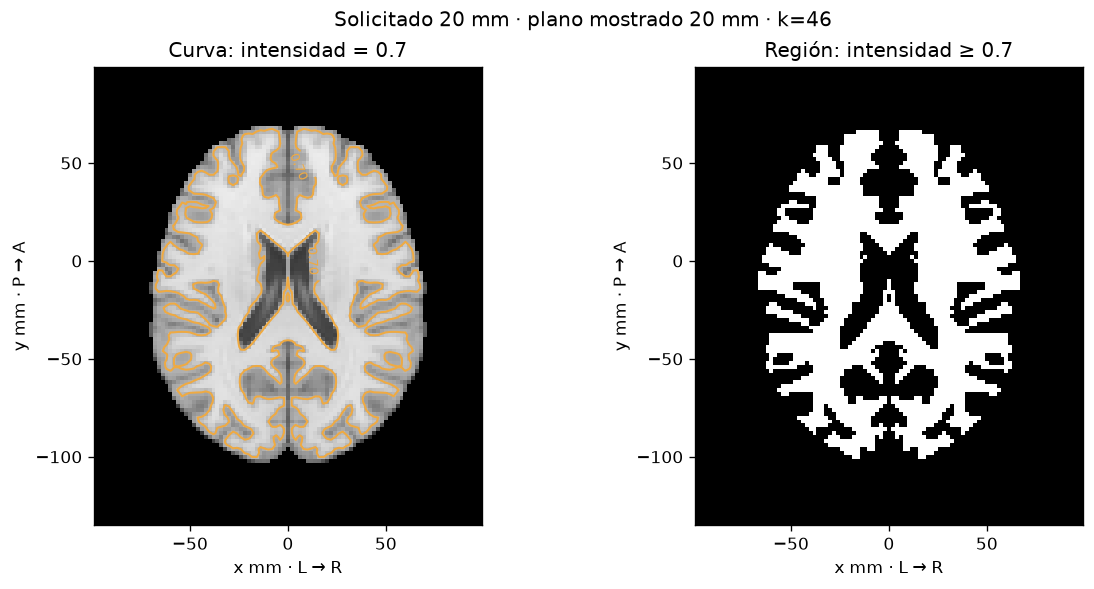

Región seleccionada: 2820 píxeles. Si no hay cruce del nivel, no aparece curva.


In [16]:
def ver_curva(z_mm, nivel):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    region = (corte > 1e-6) & (corte >= nivel)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.8), layout="constrained")
    ax[0].imshow(corte, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    if corte.min() < nivel < corte.max():
        lineas = ax[0].contour(x, y, corte, levels=[nivel], colors=["#efaa42"], linewidths=1.2)
        ax[0].clabel(lineas, fmt="%.2f", fontsize=8)
    ax[1].imshow(region, cmap="gray", origin="lower", extent=extension,
                 vmin=0, vmax=1, interpolation="nearest")
    for panel, titulo in zip(ax, [f"Curva: intensidad = {nivel:g}", f"Región: intensidad ≥ {nivel:g}"]):
        panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print(f"Región seleccionada: {region.sum()} píxeles. Si no hay cruce del nivel, no aparece curva.")
    return fig

control_curva = widgets.interactive(
    ver_curva,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    nivel=widgets.FloatSlider(value=0.7, min=0.05, max=0.95, step=0.05, continuous_update=False),
)
display(control_curva)


## 17 · Añadir ruido para comparar filtros

`default_rng(semilla)` crea un generador repetible. `normal(0,sigma_ruido,size=...)` genera una perturbación de media cero, desviación `sigma_ruido` y la forma del corte. `corte + ruido` calcula otra matriz; conserva el original.

**Cambia `sigma_ruido` de 0.06 a 0.12** para aumentar la perturbación. Usar la misma semilla permite comparar filtros sobre el mismo ruido. Este ruido artificial ilustra el procesamiento; no reproduce todas las propiedades del ruido de una resonancia. Los valores no se recortan: la ventana 0–1 sólo limita su representación.


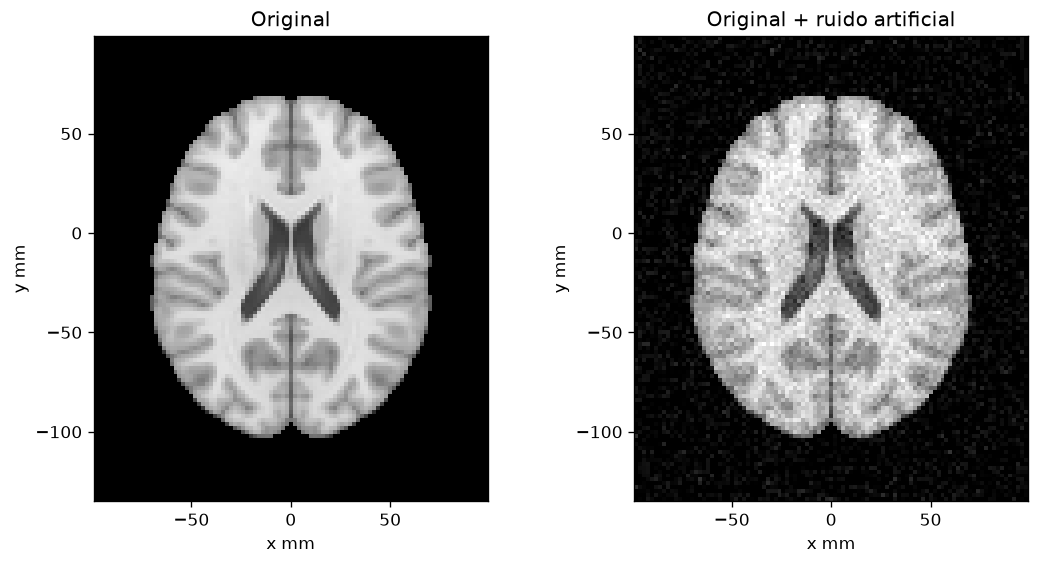

Valores con ruido: mínimo -0.239, máximo 1.110


In [17]:
semilla, sigma_ruido = 2026, 0.06
rng = np.random.default_rng(semilla)
ruido = rng.normal(0, sigma_ruido, size=corte.shape).astype(np.float32)
ruidosa = corte + ruido
fig, ax = plt.subplots(1, 2, figsize=(9, 4.6), layout="constrained")
for panel, matriz, titulo in zip(ax, [corte, ruidosa], ["Original", "Original + ruido artificial"]):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel="x mm", ylabel="y mm")
plt.show()
print(f"Valores con ruido: mínimo {ruidosa.min():.3f}, máximo {ruidosa.max():.3f}")


## 18 · Calcular una ventana de 3 × 3

Un filtro utiliza una vecindad. `.mean()` suma sus nueve valores y divide entre nueve; `np.median` los ordena y toma el quinto. Con ocho valores 10 y uno 90, la media da **18.8889** y la mediana **10**.

**Cambia el 90 en `vecindad` y ejecuta.** La media es sensible a un valor extremo; la mediana puede eliminarlo si ocupa una minoría de la ventana. Cada desplazamiento de la ventana produce un valor de salida. Al calcular una imagen completa es necesario definir cómo tratar sus límites.


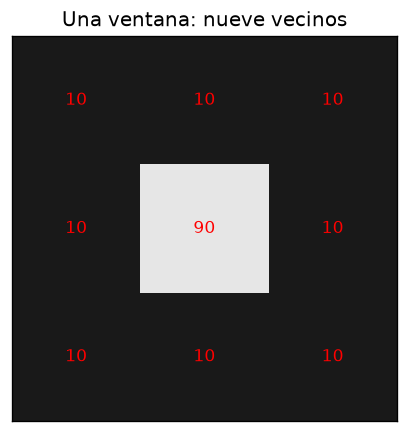

Media: 170 / 9 = 18.8889
Mediana: 10.0


In [18]:
vecindad = np.array([[10, 10, 10], [10, 90, 10], [10, 10, 10]])
fig, ax = plt.subplots(figsize=(4, 3.5), layout="constrained")
ax.imshow(vecindad, cmap="gray", vmin=0, vmax=100, interpolation="nearest")
for (fila, columna), valor in np.ndenumerate(vecindad):
    ax.text(columna, fila, str(valor), ha="center", va="center", color="red")
ax.set(title="Una ventana: nueve vecinos", xticks=[], yticks=[])
plt.show()
print(f"Media: {vecindad.sum()} / {vecindad.size} = {vecindad.mean():.4f}")
print("Mediana:", np.median(vecindad))


## 19 · Comparar media, Gauss y mediana

**Mueve `sigma_px` y `ruido_sd`.** `uniform_filter(...,size=3)` calcula medias 3 × 3; `median_filter` toma medianas; `gaussian_filter(...,sigma=...)` pondera más los vecinos cercanos. `mode="reflect"` prolonga la imagen por reflexión para tratar sus límites.

`sigma_px` mide la anchura de Gauss en píxeles por eje; `ruido_sd` mide amplitud de intensidad. No son lo mismo. Multiplicar sigma por 2 mm convierte su escala espacial en milímetros. Un sigma mayor suaviza más y puede borrar detalles.

La función genera siempre el mismo patrón aleatorio con semilla 2026. Los filtros reciben la misma entrada. `ax.ravel()` permite recorrer los cuatro paneles, todos con la ventana 0–1: así se comparan números equivalentes. A diferencia del contraste, **filtrar sí calcula valores nuevos**.


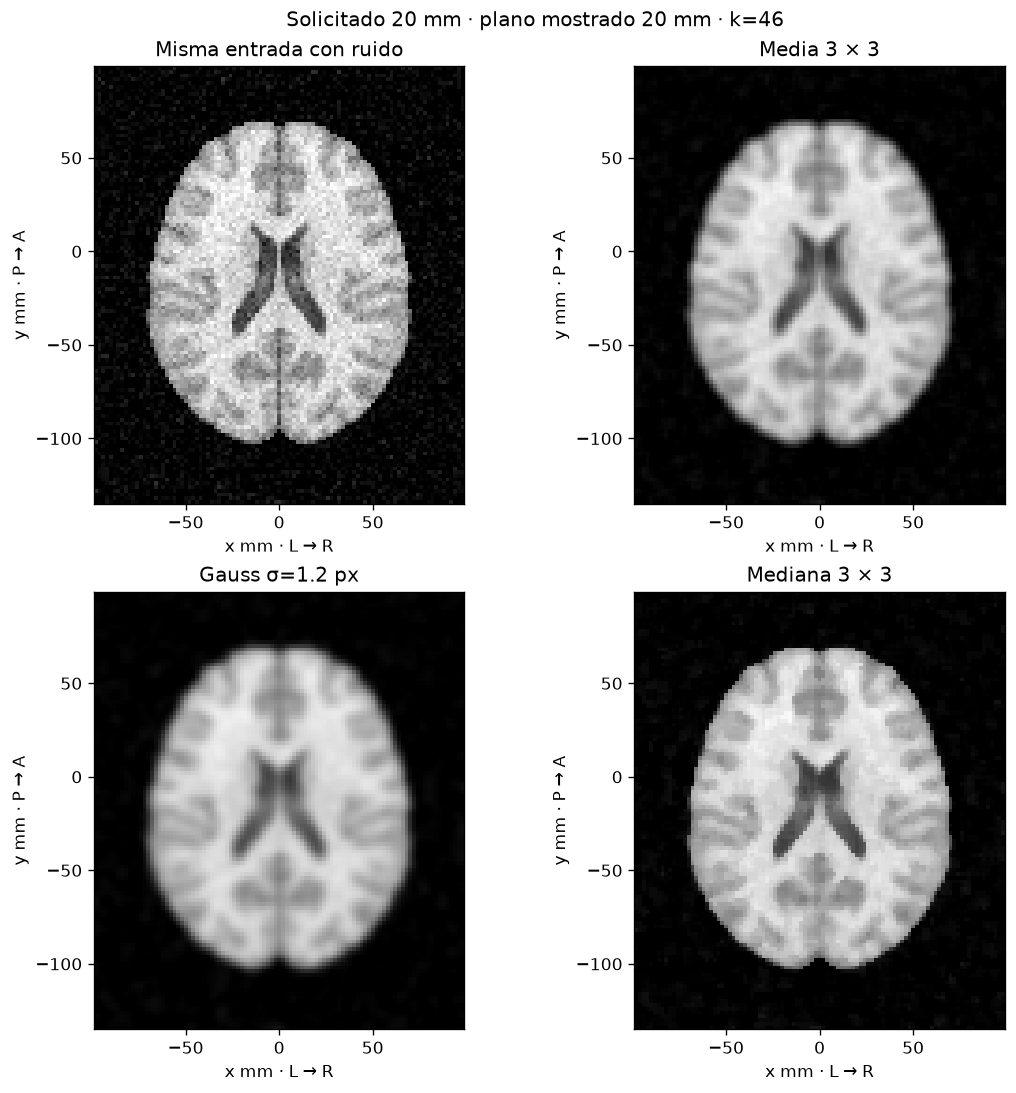

Sigma Gauss: 2.4 mm por eje · ruido SD: 0.06


In [19]:
def ver_filtros(z_mm, sigma_px, ruido_sd):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    rng = np.random.default_rng(2026)
    ruidosa = corte + rng.normal(0, ruido_sd, size=corte.shape).astype(np.float32)
    media = ndimage.uniform_filter(ruidosa, size=3, mode="reflect")
    gauss = ndimage.gaussian_filter(ruidosa, sigma=sigma_px, mode="reflect")
    mediana = ndimage.median_filter(ruidosa, size=3, mode="reflect")
    matrices = [ruidosa, media, gauss, mediana]
    titulos = ["Misma entrada con ruido", "Media 3 × 3", f"Gauss σ={sigma_px:g} px", "Mediana 3 × 3"]
    fig, ax = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
    for panel, matriz, titulo in zip(ax.ravel(), matrices, titulos):
        panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
        panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print(f"Sigma Gauss: {sigma_px*pasos[0]:g} mm por eje · ruido SD: {ruido_sd:g}")
    return fig

control_filtros = widgets.interactive(
    ver_filtros,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    sigma_px=widgets.FloatSlider(value=1.2, min=0, max=3, step=0.1, continuous_update=False),
    ruido_sd=widgets.FloatSlider(value=0.06, min=0, max=0.2, step=0.01, continuous_update=False),
)
display(control_filtros)


## 20 · Un borde es un cambio entre vecinos

`np.diff(fila)` calcula cada valor menos el anterior. `np.abs` elimina el signo y conserva la magnitud del cambio. Una fila de 9 píxeles produce 8 diferencias porque hay 8 parejas consecutivas.

**Prueba `fila = np.full(9, 0.8)`**: es brillante y uniforme, por lo que todas las diferencias son cero. El salto de la fila inicial produce una diferencia grande. `plot` une las intensidades y `bar` dibuja las magnitudes de las diferencias. Esta operación es un ejemplo 1D; Sobel combina cambios en dos direcciones de una imagen.


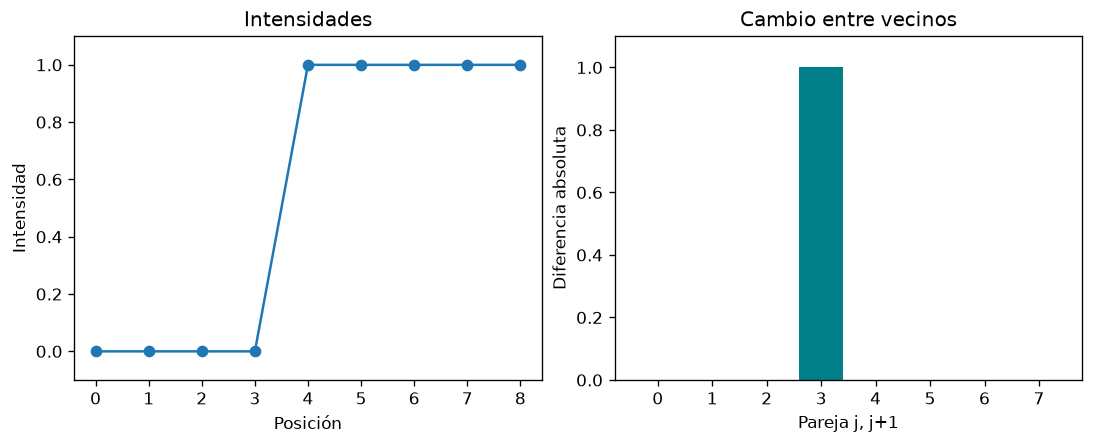

Diferencias: [0. 0. 0. 1. 0. 0. 0. 0.]


In [20]:
fila = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1], dtype=float)
diferencias = np.diff(fila)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
ax[0].plot(fila, "o-")
ax[0].set(title="Intensidades", xlabel="Posición", ylabel="Intensidad", ylim=(-0.1, 1.1))
ax[1].bar(np.arange(diferencias.size), np.abs(diferencias), color="#007f89")
ax[1].set(title="Cambio entre vecinos", xlabel="Pareja j, j+1", ylabel="Diferencia absoluta", ylim=(0, 1.1))
plt.show()
print("Diferencias:", diferencias)


## 21 · Medir cambios con Sobel

`sobel(...,axis=1)` responde a cambios entre columnas y `axis=0`, entre filas. `np.sqrt(dx**2+dy**2)` combina ambas respuestas en una magnitud sin signo. `return` devuelve esa matriz para poder dibujarla.

`imshow(...,cmap="magma")` representa la magnitud con colores; `colorbar` explica su escala. Una respuesta grande significa cambio local, que puede deberse a una estructura o a ruido. Esta respuesta de Sobel no está normalizada como una derivada física por milímetro.


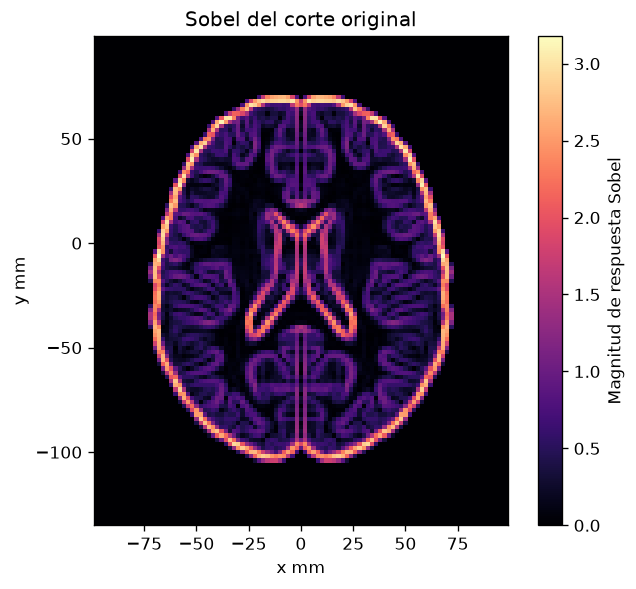

In [21]:
def magnitud_sobel(matriz):
    dx = ndimage.sobel(matriz, axis=1, mode="reflect")
    dy = ndimage.sobel(matriz, axis=0, mode="reflect")
    return np.sqrt(dx**2 + dy**2)

gradiente = magnitud_sobel(corte)
fig, ax = plt.subplots(figsize=(6, 4.8), layout="constrained")
mapa = ax.imshow(gradiente, cmap="magma", origin="lower", extent=extension, vmin=0)
ax.set(title="Sobel del corte original", xlabel="x mm", ylabel="y mm")
fig.colorbar(mapa, ax=ax, label="Magnitud de respuesta Sobel")
plt.show()


## 22 · Comparar bordes antes y después de suavizar

**Mueve `sigma_px`, `ruido_sd` y `umbral`.** La función añade el mismo ruido, calcula Gauss y aplica Sobel antes y después. `max(...)` fija un máximo común para ambos mapas: el mismo color tiene el mismo significado. `1e-12` evita una escala de ancho cero.

`antes >= umbral` y `despues >= umbral` seleccionan respuestas suficientemente grandes. `enumerate` entrega índice y panel; el índice decide si mostrar magnitud o máscara. `colorbar` corresponde a los dos mapas de magnitud. La selección depende de los parámetros: reducir ruido puede ayudar, pero suavizar también puede borrar bordes pequeños.


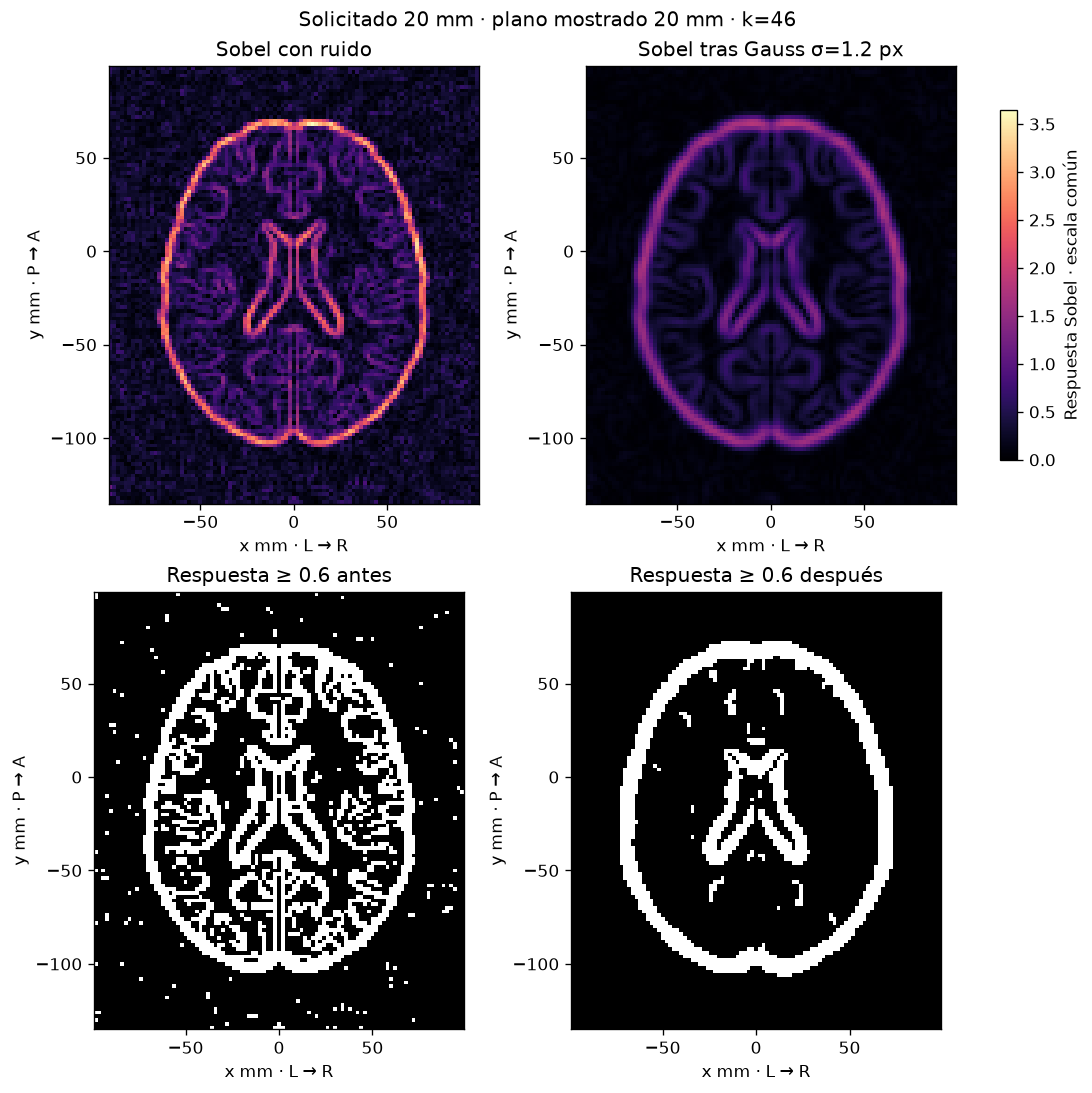

Umbral 0.6: seleccionados antes/después = 2471 / 1495


In [22]:
def ver_bordes(z_mm, sigma_px, ruido_sd, umbral):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    rng = np.random.default_rng(2026)
    ruidosa = corte + rng.normal(0, ruido_sd, size=corte.shape).astype(np.float32)
    gauss = ndimage.gaussian_filter(ruidosa, sigma=sigma_px, mode="reflect")
    antes, despues = magnitud_sobel(ruidosa), magnitud_sobel(gauss)
    maximo = max(float(antes.max()), float(despues.max()), 1e-12)
    mapas = [antes, despues, antes >= umbral, despues >= umbral]
    titulos = ["Sobel con ruido", f"Sobel tras Gauss σ={sigma_px:g} px",
               f"Respuesta ≥ {umbral:g} antes", f"Respuesta ≥ {umbral:g} después"]
    fig, ax = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
    for i, panel in enumerate(ax.ravel()):
        panel.imshow(mapas[i], cmap="magma" if i < 2 else "gray", origin="lower",
                     extent=extension, vmin=0, vmax=maximo if i < 2 else 1)
        panel.set(title=titulos[i], xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.colorbar(ax[0, 0].images[0], ax=ax[0, :], shrink=0.8, label="Respuesta Sobel · escala común")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print(f"Umbral {umbral:g}: seleccionados antes/después = {(antes >= umbral).sum()} / {(despues >= umbral).sum()}")
    return fig

control_bordes = widgets.interactive(
    ver_bordes,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    sigma_px=widgets.FloatSlider(value=1.2, min=0, max=3, step=0.1, continuous_update=False),
    ruido_sd=widgets.FloatSlider(value=0.06, min=0, max=0.2, step=0.01, continuous_update=False),
    umbral=widgets.FloatSlider(value=0.6, min=0, max=2, step=0.05, continuous_update=False),
)
display(control_bordes)


**Fuentes:** [plantilla de Nilearn](https://nilearn.github.io/stable/modules/generated/nilearn.datasets.load_mni152_template.html), [elementos de pydicom](https://pydicom.github.io/pydicom/stable/guides/user/base_element.html), [lectura de DICOM](https://pydicom.github.io/pydicom/stable/reference/generated/pydicom.filereader.dcmread.html), [geometría DICOM](https://dicom.nema.org/medical/DICOM/current/output/chtml/part03/sect_C.7.6.2.html) y [opciones de desidentificación](https://dicom.nema.org/medical/dicom/current/output/chtml/part15/sect_E.3.html).
